# Quy trình tiền xử lý dữ liệu Bank Marketing

Notebook này thực hiện tuần tự các bước kiểm tra chất lượng dữ liệu, xử lý missing/unknown, trùng lặp, ngoại lệ, mã hóa, scaling, phân tích tương quan, đánh giá mất cân bằng lớp và xuất dữ liệu đã chuẩn hóa.

## Bước 1 - Tải dữ liệu và cấu hình môi trường

Khai báo các thư viện chính. `numpy`, `pandas` dùng để xử lý dữ liệu; `matplotlib` và `seaborn` dùng để trực quan hóa; `StandardScaler` và `RobustScaler` hỗ trợ chuẩn hóa đặc trưng.

In [120]:
!python -m pip install numpy pandas matplotlib seaborn scikit-learn imbalanced-learn

In [121]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, RobustScaler

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid', palette='Set2')
RANDOM_STATE = 42


Đọc dữ liệu bằng dấu phân cách `;` theo đúng định dạng của bộ Bank Marketing. Các lệnh `head`, `tail`, `shape`, `info` và `dtypes` giúp xác nhận dữ liệu đã được đọc đúng.

In [122]:
data = pd.read_csv('./bank-full.csv', sep=';')
print('5 dòng đầu:')
display(data.head())
print('5 dòng cuối:')
display(data.tail())
print(f'Kích thước dữ liệu: {data.shape}')
print('\nThông tin tổng quát:')
data.info()
print('\nKiểu dữ liệu từng cột:')
display(data.dtypes.to_frame('dtype'))

5 dòng đầu:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


5 dòng cuối:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no
45210,37,entrepreneur,married,secondary,no,2971,no,no,cellular,17,nov,361,2,188,11,other,no


Kích thước dữ liệu: (45211, 17)

Thông tin tổng quát:
<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB

Kiểu dữ liệu từng cột:


,dtype
age,int64
job,str
marital,str
education,str
default,str
balance,int64
housing,str
loan,str
contact,str
day,int64


## Bước 2 - Kiểm tra và xử lý giá trị thiếu

Kiểm tra đồng thời giá trị `null` thực sự và chuỗi `unknown`. Trong bộ dữ liệu này, `unknown` là một trạng thái có ý nghĩa (ví dụ chưa biết phương thức liên hệ hoặc kết quả chiến dịch trước), vì vậy được giữ lại như một nhóm phân loại thay vì xóa hoặc thay bằng mode. `null` nếu xuất hiện sẽ được điền mode với cột phân loại và median với cột số.

,null_count,unknown_count,total_missing_or_unknown,percentage
poutcome,0,36959,36959,81.747805
contact,0,13020,13020,28.798301
education,0,1857,1857,4.107407
job,0,288,288,0.637013
age,0,0,0,0.000000
default,0,0,0,0.000000
balance,0,0,0,0.000000
housing,0,0,0,0.000000
marital,0,0,0,0.000000
loan,0,0,0,0.000000


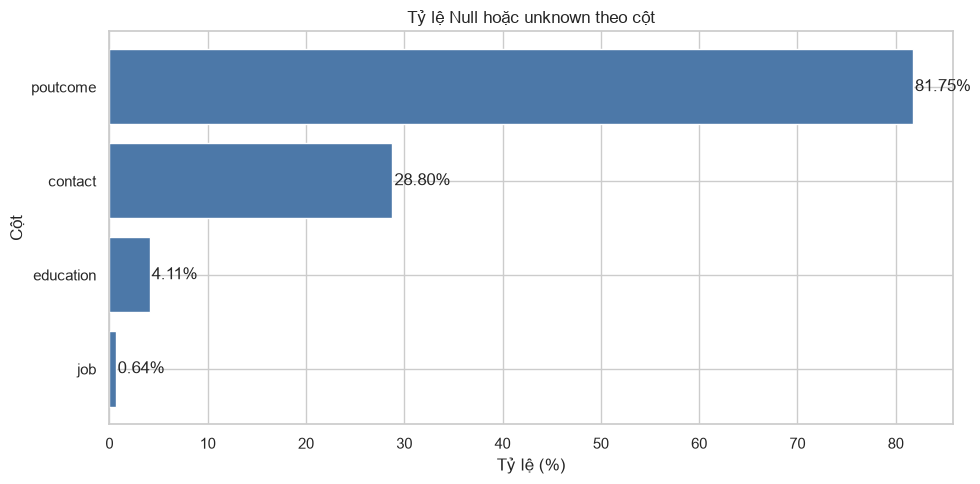

Tổng số null sau xử lý: 0


In [123]:
numeric_columns = data.select_dtypes(include=np.number).columns.tolist()
categorical_columns = data.select_dtypes(exclude=np.number).columns.tolist()

null_count = data.isna().sum()
unknown_count = data.eq('unknown').sum()
missing_report = pd.DataFrame({
    'null_count': null_count,
    'unknown_count': unknown_count,
    'total_missing_or_unknown': null_count + unknown_count,
})
missing_report['percentage'] = missing_report['total_missing_or_unknown'] / len(data) * 100
display(missing_report.sort_values('total_missing_or_unknown', ascending=False))

plot_report = missing_report[missing_report['total_missing_or_unknown'] > 0].sort_values('percentage')
plt.figure(figsize=(10, 5))
bars = plt.barh(plot_report.index, plot_report['percentage'], color='#4C78A8')
plt.title('Tỷ lệ Null hoặc unknown theo cột')
plt.xlabel('Tỷ lệ (%)')
plt.ylabel('Cột')
for bar, value in zip(bars, plot_report['percentage']):
    plt.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height() / 2, f'{value:.2f}%', va='center')
plt.tight_layout()
plt.show()

for column in numeric_columns:
    if data[column].isna().any():
        data[column] = data[column].fillna(data[column].median())
for column in categorical_columns:
    if data[column].isna().any():
        data[column] = data[column].fillna(data[column].mode().iloc[0])
print('Tổng số null sau xử lý:', int(data.isna().sum().sum()))


Biểu đồ cho thấy các cột có `unknown` cần được xem như một mức phân loại hợp lệ. Sau bước này, dữ liệu không còn null; các giá trị `unknown` vẫn được bảo toàn để không làm mất thông tin.

## Bước 3 - Kiểm tra và xử lý dữ liệu trùng lặp

Các bản ghi trùng hoàn toàn không mang thêm thông tin và có thể làm sai lệch phân phối. Vì vậy, loại bỏ chúng rồi tạo lại chỉ mục liên tục.

In [124]:
duplicate_count = int(data.duplicated().sum())
print(f'Số dòng trùng lặp: {duplicate_count}')
data = data.drop_duplicates().reset_index(drop=True)
print(f'Kích thước sau khi xử lý trùng lặp: {data.shape}')

Số dòng trùng lặp: 0
Kích thước sau khi xử lý trùng lặp: (45211, 17)


## Bước 4 - Phân tích và xử lý giá trị ngoại lệ

IQR xác định ngưỡng dưới và trên bằng công thức `Q1 - 1.5*IQR` và `Q3 + 1.5*IQR`. Vì các biến như `balance`, `duration`, `campaign` có thể chứa giá trị lớn nhưng vẫn hợp lệ, ta giới hạn (capping) tại ngưỡng IQR thay vì xóa toàn bộ dòng. `pdays` có giá trị đặc biệt `-1` biểu thị chưa từng được liên hệ, còn `previous` thường bằng 0; hai quy ước này được giữ nguyên để không làm mất ngữ nghĩa miền dữ liệu.

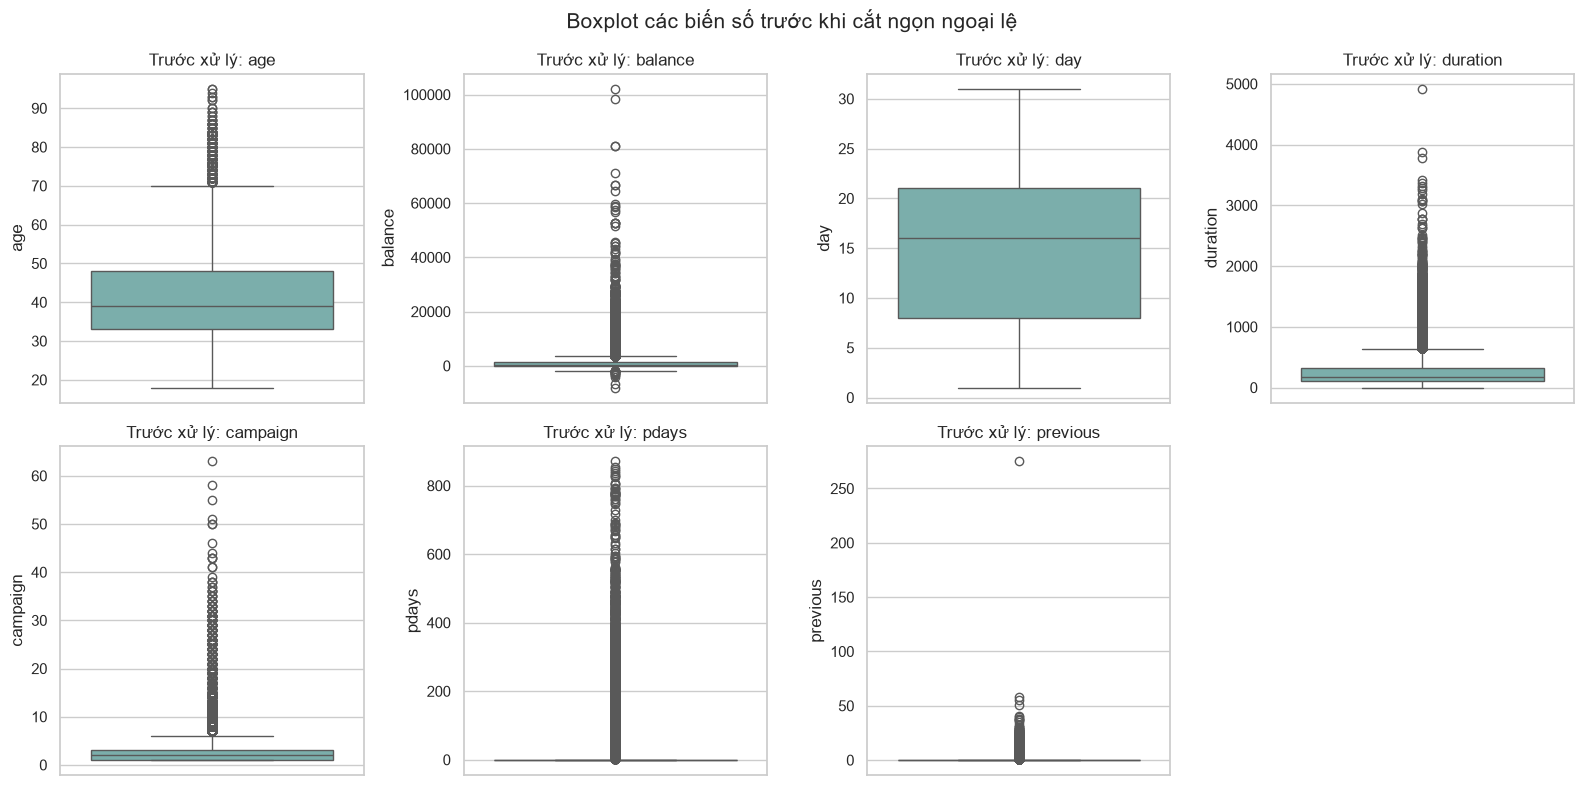

age          487
balance     4729
day            0
duration    3235
campaign    3064
Name: số ngoại lệ trước capping, dtype: int64

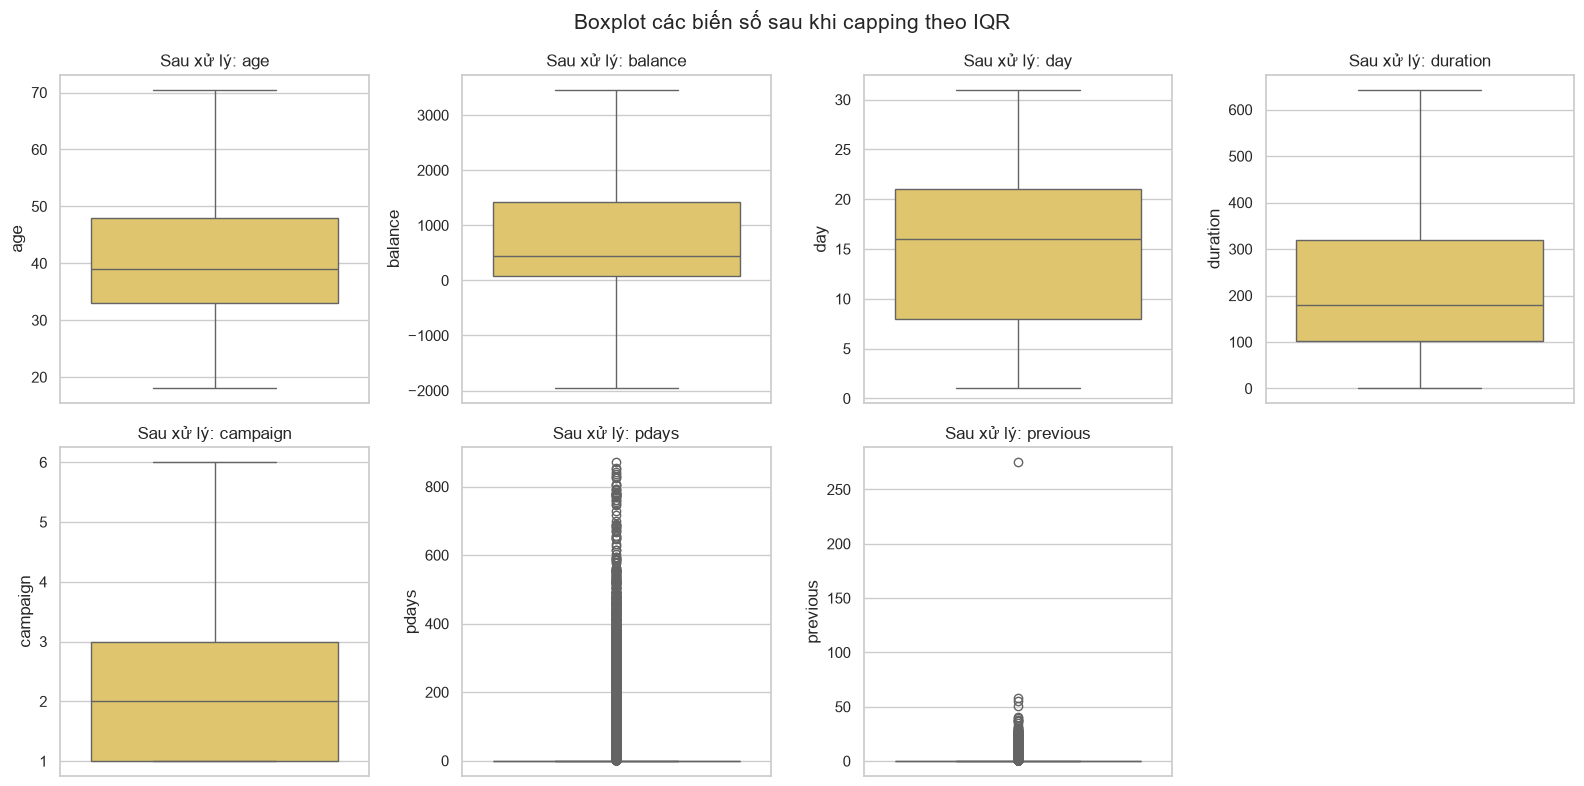

In [125]:
numeric_columns = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
capping_columns = ['age', 'balance', 'day', 'duration', 'campaign']

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for axis, column in zip(axes.flat, numeric_columns):
    sns.boxplot(y=data[column], ax=axis, color='#72B7B2')
    axis.set_title(f'Trước xử lý: {column}')
    axis.set_ylabel(column)
axes.flat[-1].axis('off')
fig.suptitle('Boxplot các biến số trước khi cắt ngọn ngoại lệ', fontsize=15)
plt.tight_layout()
plt.show()

outlier_summary = {}
for column in capping_columns:
    q1, q3 = data[column].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_summary[column] = int(((data[column] < lower) | (data[column] > upper)).sum())
    data[column] = data[column].clip(lower=lower, upper=upper)
display(pd.Series(outlier_summary, name='số ngoại lệ trước capping'))

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for axis, column in zip(axes.flat, numeric_columns):
    sns.boxplot(y=data[column], ax=axis, color='#F2CF5B')
    axis.set_title(f'Sau xử lý: {column}')
    axis.set_ylabel(column)
axes.flat[-1].axis('off')
fig.suptitle('Boxplot các biến số sau khi capping theo IQR', fontsize=15)
plt.tight_layout()
plt.show()

## Bước 5 - Mã hóa biến phân loại

Các biến nhị phân `yes/no` được ánh xạ thành 1/0. `education` có thứ tự tự nhiên và `month` được mã hóa theo thứ tự tháng trong năm. Các biến danh nghĩa được one-hot encoding để không áp đặt quan hệ thứ tự giả. So sánh số lượng cột trước và sau encoding cho thấy không gian đặc trưng tăng do các nhóm category.

Số cột trước encoding: 17
Số cột sau encoding: 35


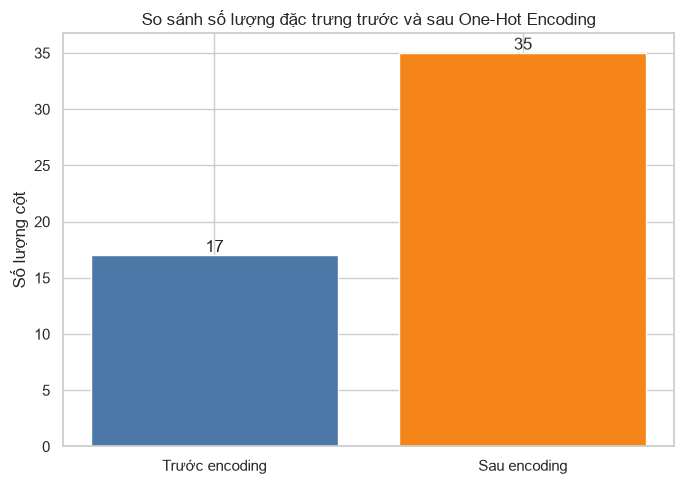

In [126]:
features_before_encoding = data.shape[1]
binary_columns = ['default', 'housing', 'loan', 'y']
for column in binary_columns:
    data[column] = data[column].map({'no': 0, 'yes': 1}).astype('int8')

education_order = {'unknown': 0, 'primary': 1, 'secondary': 2, 'tertiary': 3}
month_order = {'jan': 1, 'feb': 2, 'mar': 3, 'apr': 4, 'may': 5, 'jun': 6,
               'jul': 7, 'aug': 8, 'sep': 9, 'oct': 10, 'nov': 11, 'dec': 12}
data['education'] = data['education'].map(education_order).astype('int8')
data['month'] = data['month'].map(month_order).astype('int8')

nominal_columns = ['job', 'marital', 'contact', 'poutcome']
data = pd.get_dummies(data, columns=nominal_columns, dtype='int8')
features_after_encoding = data.shape[1]
print(f'Số cột trước encoding: {features_before_encoding}')
print(f'Số cột sau encoding: {features_after_encoding}')

plt.figure(figsize=(7, 5))
bars = plt.bar(['Trước encoding', 'Sau encoding'], [features_before_encoding, features_after_encoding],
               color=['#4C78A8', '#F58518'])
plt.title('So sánh số lượng đặc trưng trước và sau One-Hot Encoding')
plt.ylabel('Số lượng cột')
for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3, int(bar.get_height()), ha='center')
plt.tight_layout()
plt.show()

## Bước 6 - Chuẩn hóa và biến đổi thang đo

Skewness cho biết mức độ lệch của phân phối. Các biến số của dữ liệu tài chính thường có đuôi dài, nên `RobustScaler` phù hợp hơn vì dùng median và IQR, ít nhạy với giá trị cực trị. Biểu đồ hai cột bên dưới so sánh phân phối trước và sau khi scaling.

,skewness
previous,41.846454
pdays,2.615715
campaign,1.099115
balance,1.097802
duration,1.037574
age,0.529715
day,0.093079


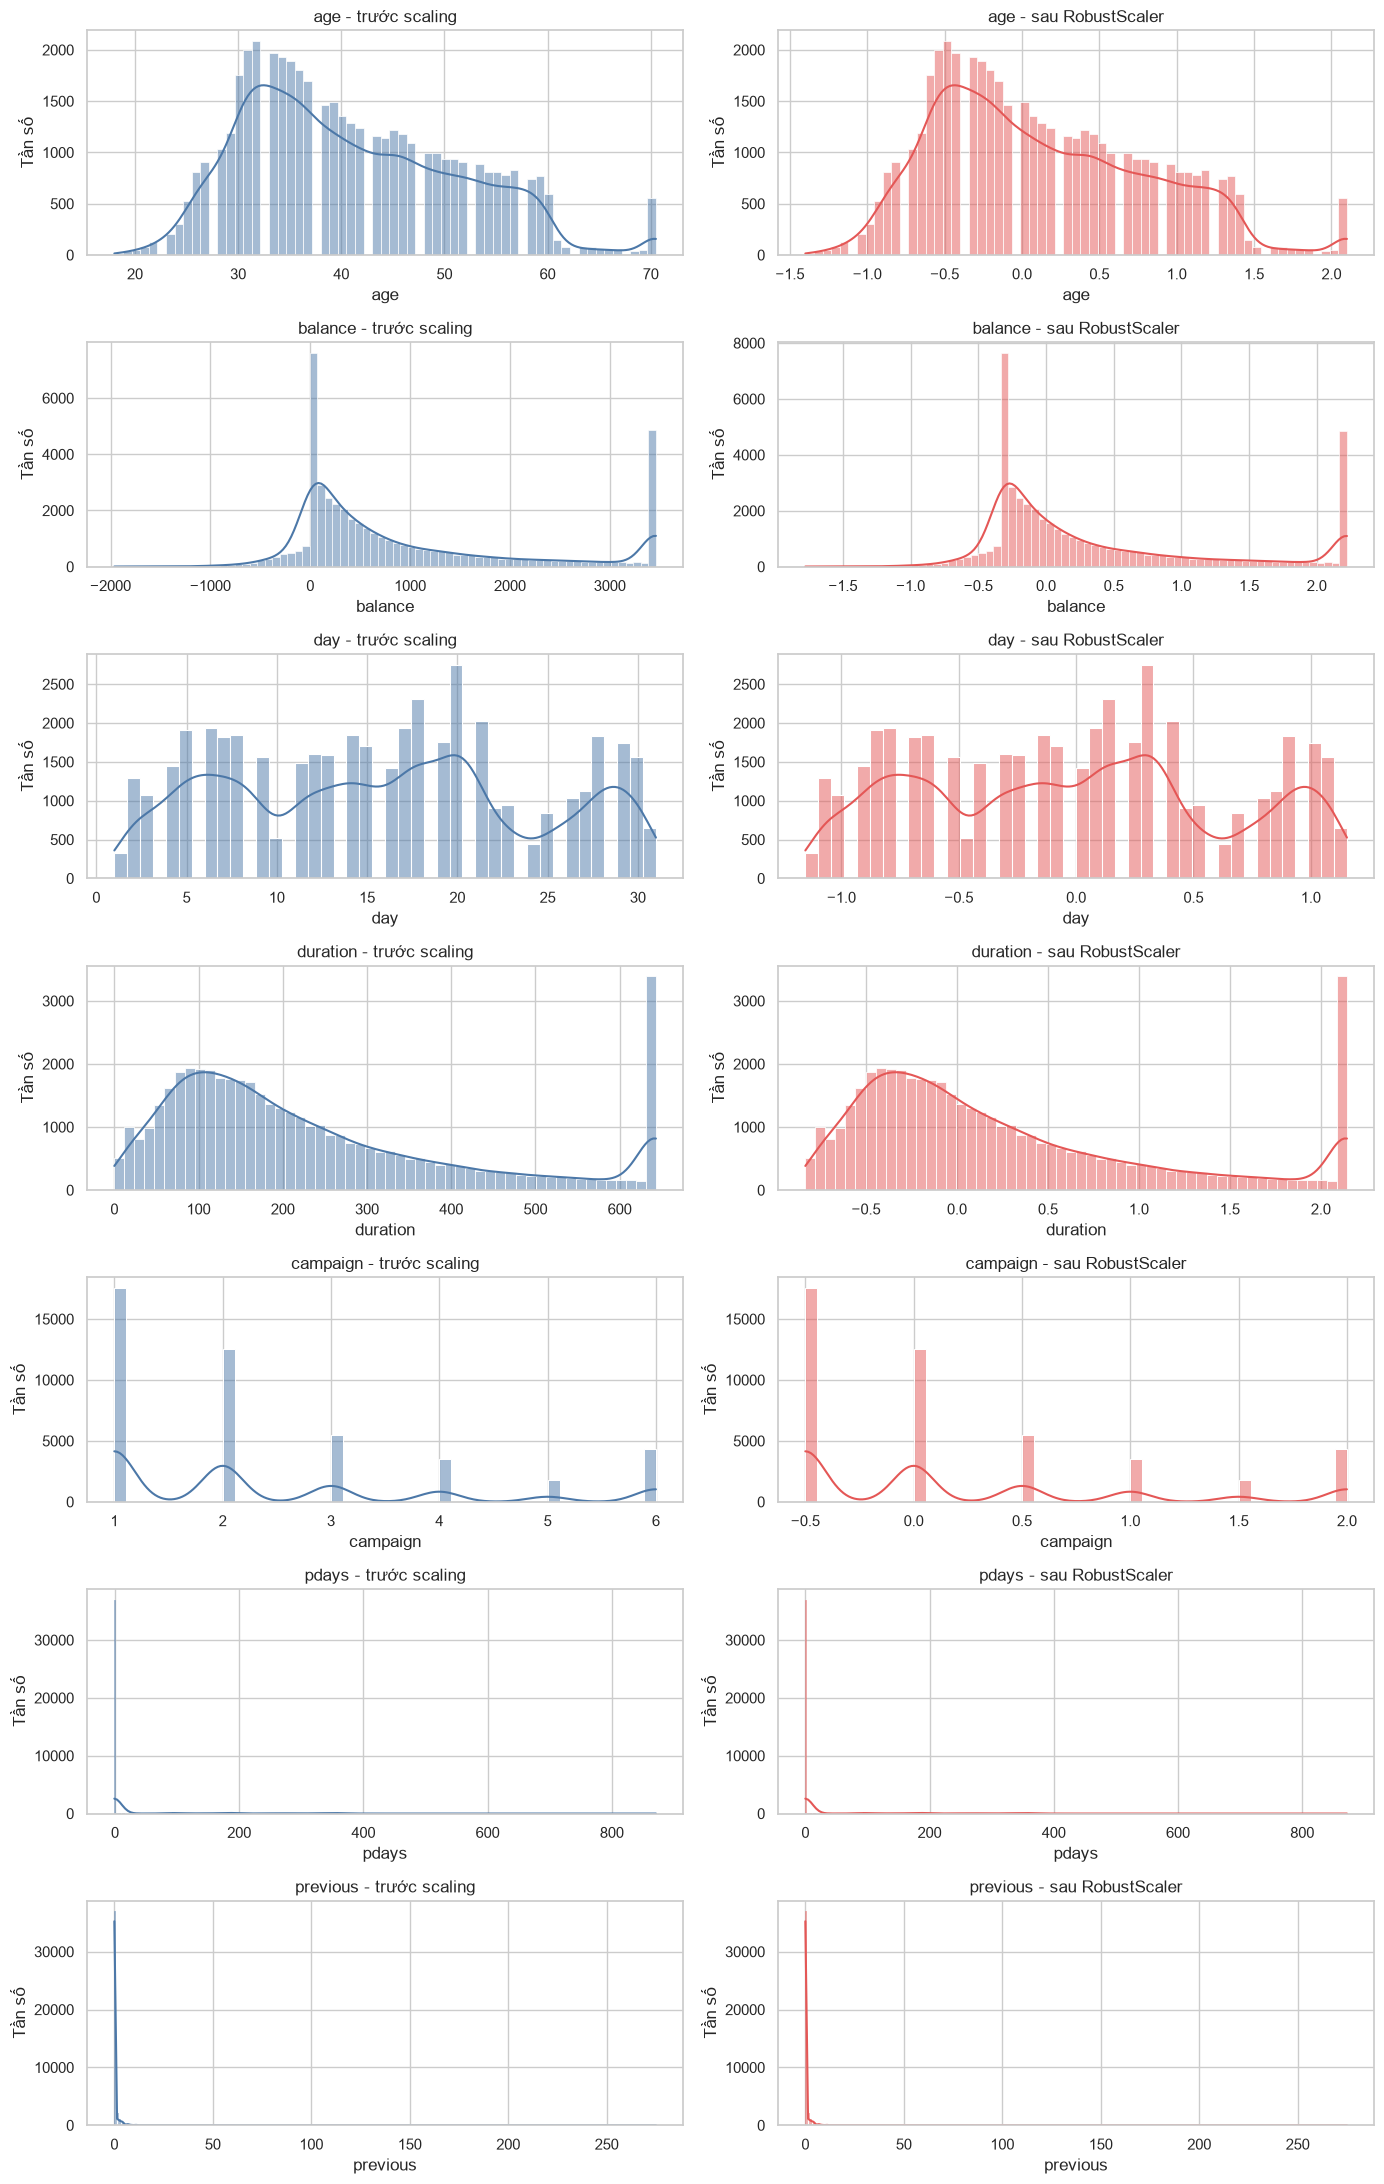

,mean,50%,std,min,max
age,0.124546,0.0,0.692993,-1.400000,2.100000
balance,0.358191,0.0,0.867821,-1.777286,2.222714
day,-0.014891,0.0,0.640190,-1.153846,1.153846
duration,0.254349,0.0,0.818287,-0.833333,2.143519
campaign,0.196114,0.0,0.800055,-0.500000,2.000000
pdays,41.197828,0.0,100.128746,0.000000,872.000000
previous,0.580323,0.0,2.303441,0.000000,275.000000


In [127]:
skewness = data[numeric_columns].skew().sort_values(ascending=False)
display(skewness.to_frame('skewness'))

scaler = RobustScaler()
scaled_values = scaler.fit_transform(data[numeric_columns])
scaled_data = data.copy()
scaled_data[numeric_columns] = scaled_values

fig, axes = plt.subplots(len(numeric_columns), 2, figsize=(14, 22))
for row, column in enumerate(numeric_columns):
    sns.histplot(data[column], kde=True, ax=axes[row, 0], color='#4C78A8')
    axes[row, 0].set_title(f'{column} - trước scaling')
    axes[row, 0].set_xlabel(column)
    axes[row, 0].set_ylabel('Tần số')
    sns.histplot(scaled_data[column], kde=True, ax=axes[row, 1], color='#E45756')
    axes[row, 1].set_title(f'{column} - sau RobustScaler')
    axes[row, 1].set_xlabel(column)
    axes[row, 1].set_ylabel('Tần số')
plt.tight_layout()
plt.show()

data = scaled_data
display(data[numeric_columns].describe().T[['mean', '50%', 'std', 'min', 'max']])

## Bước 7 - Phân tích tương quan và đa cộng tuyến

Ma trận tương quan Pearson cho biết quan hệ tuyến tính giữa các biến. Tương quan dương gần 1 hoặc âm gần -1 là mạnh; các cặp đặc trưng có trị tuyệt đối cao có thể gây đa cộng tuyến. Với dữ liệu này, `duration` thường là biến liên hệ đáng chú ý với mục tiêu, nhưng tương quan không chứng minh quan hệ nhân quả.

Tương quan với biến mục tiêu y:


,correlation_with_y
duration,0.390659
poutcome_success,0.306788
poutcome_unknown,-0.167051
contact_unknown,-0.150935
housing,-0.139173
contact_cellular,0.135873
pdays,0.103621
previous,0.093236
balance,0.092924
campaign,-0.084061


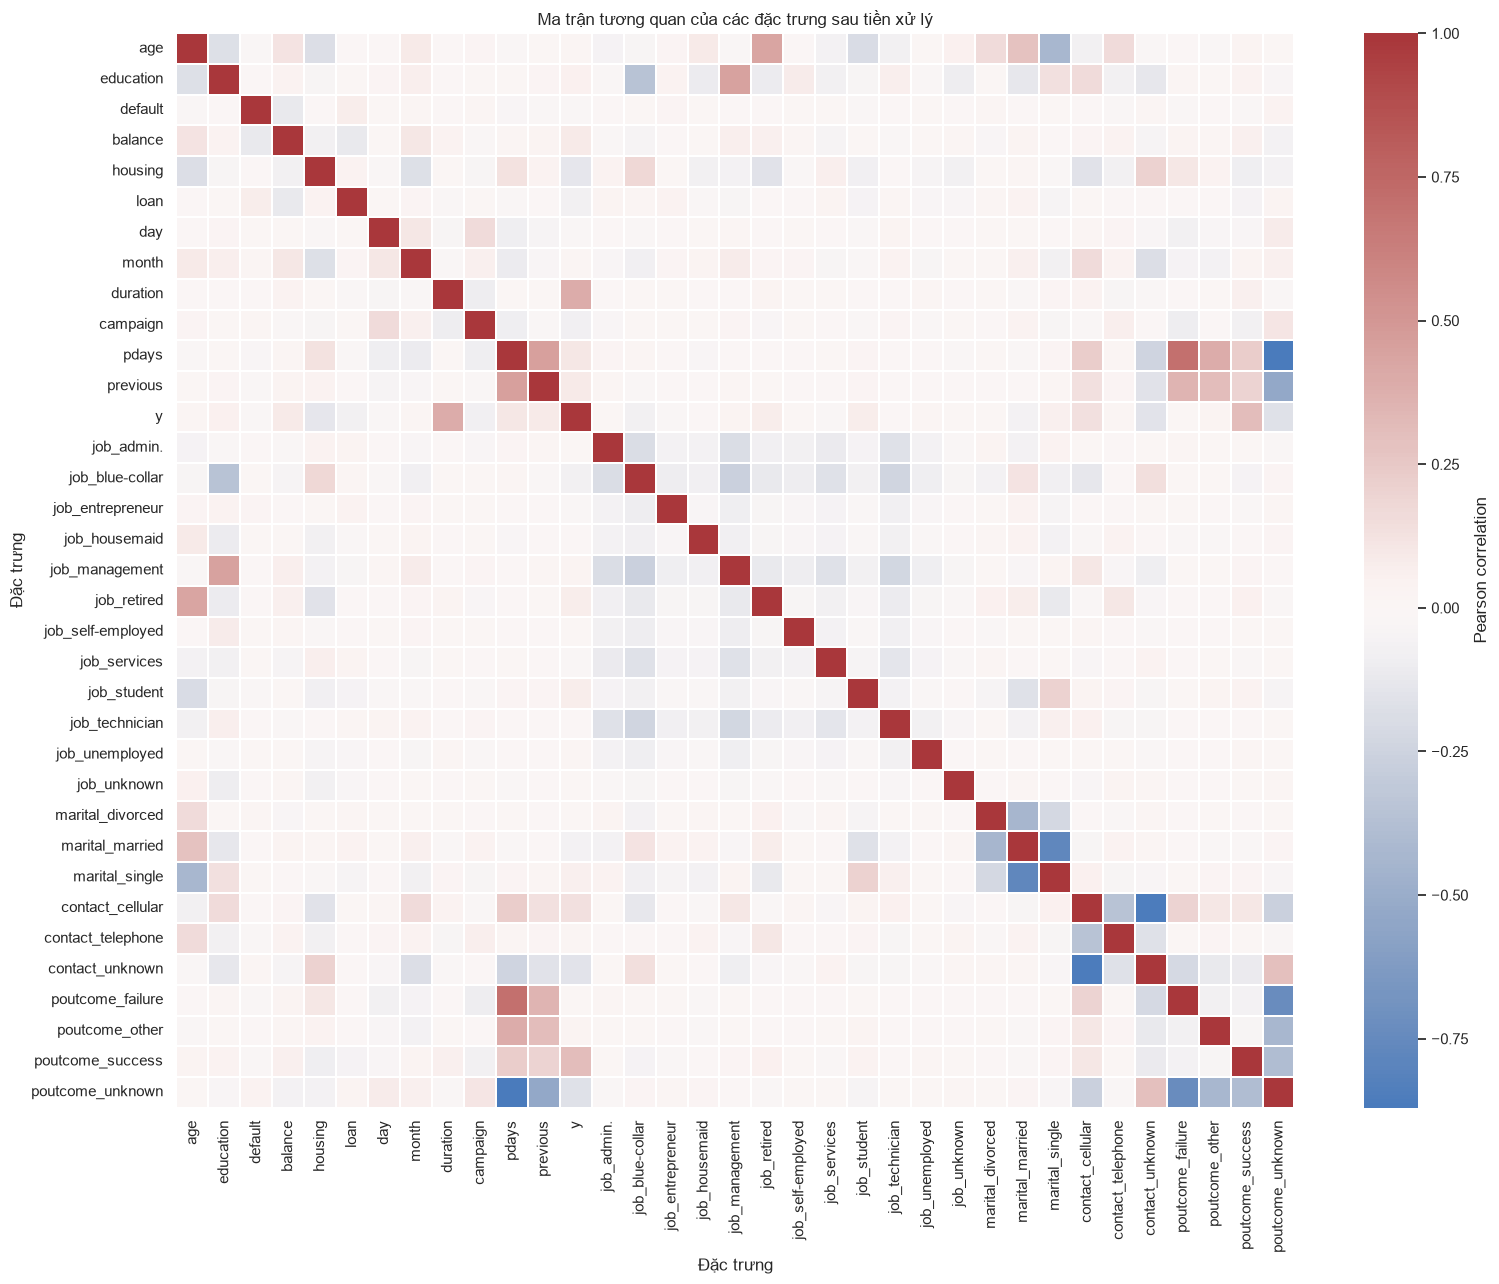

Các cặp đặc trưng có tương quan tuyệt đối cao nhất:


,,absolute_correlation
pdays,poutcome_unknown,0.869962
contact_cellular,contact_unknown,0.862398
marital_married,marital_single,0.772357
poutcome_failure,poutcome_unknown,0.737932
pdays,poutcome_failure,0.701052
previous,poutcome_unknown,0.532763
pdays,previous,0.454820
education,job_management,0.450484
marital_divorced,marital_married,0.443648
poutcome_other,poutcome_unknown,0.435903


In [128]:
correlation_matrix = data.corr(numeric_only=True)
target_correlation = correlation_matrix['y'].drop('y').sort_values(key=np.abs, ascending=False)
print('Tương quan với biến mục tiêu y:')
display(target_correlation.to_frame('correlation_with_y').head(10))

plt.figure(figsize=(16, 13))
sns.heatmap(correlation_matrix, cmap='vlag', center=0, linewidths=0.2, cbar_kws={'label': 'Pearson correlation'})
plt.title('Ma trận tương quan của các đặc trưng sau tiền xử lý')
plt.xlabel('Đặc trưng')
plt.ylabel('Đặc trưng')
plt.tight_layout()
plt.show()

upper_triangle = correlation_matrix.where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool))
strong_pairs = (upper_triangle.stack().abs().sort_values(ascending=False).to_frame('absolute_correlation'))
print('Các cặp đặc trưng có tương quan tuyệt đối cao nhất:')
display(strong_pairs.head(10))

## Bước 8 - Tách dữ liệu và xử lý mất cân bằng lớp bằng SMOTE

Tách tập train/test trước khi cân bằng để tránh Data Leakage. Tham số `stratify=y` giữ nguyên tỷ lệ khoảng 88% `no` và 12% `yes` ở cả hai tập. SMOTE chỉ được áp dụng trên tập train bằng `fit_resample`; tập test giữ nguyên phân phối thực tế để đánh giá khách quan. Khi đánh giá mô hình, nên ưu tiên F1-Score, Precision-Recall AUC (PR-AUC), Precision và Recall thay vì chỉ dùng Accuracy.


Phân phối y ban đầu:


y
0    88.3
1    11.7
Name: percentage, dtype: float64

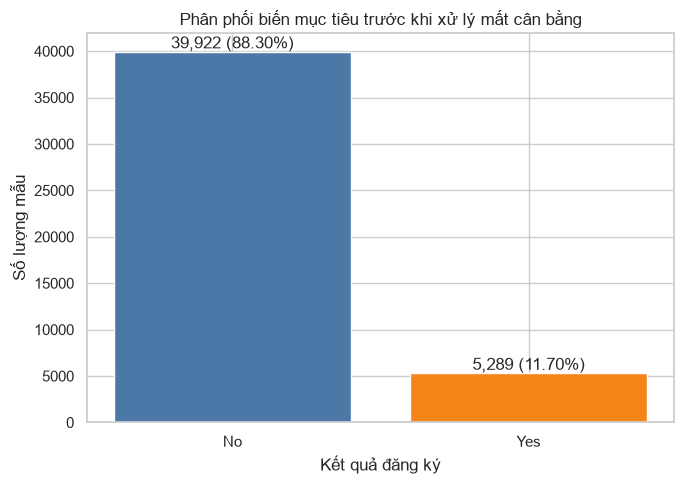

y_train trước SMOTE:
y
0    31937
1     4231
Name: count, dtype: int64

y_train_resampled sau SMOTE:
y
0    31937
1    31937
Name: count, dtype: int64


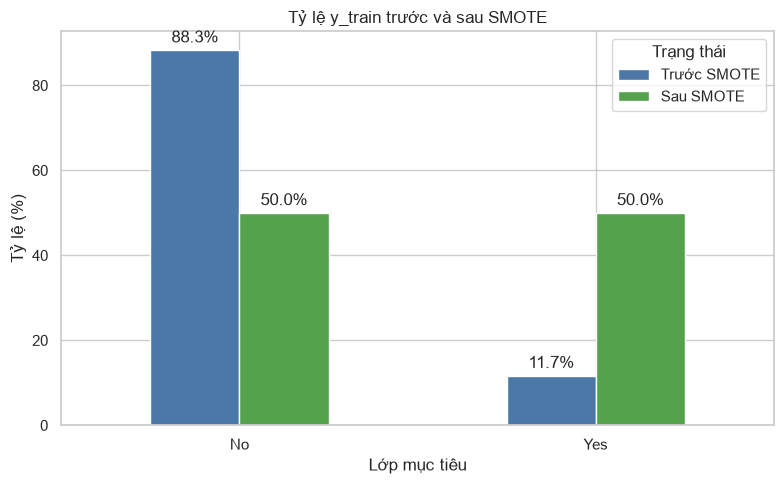

Kích thước X_train: (36168, 34)
Kích thước X_train_resampled: (63874, 34)
Kích thước X_test: (9043, 34)
Tỷ lệ y_test được giữ nguyên sau khi chỉ SMOTE tập train:


y
0    88.3
1    11.7
Name: percentage, dtype: float64

In [129]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

X = data.drop(columns='y')
y = data['y']

# Split data into training and testing sets with stratification to maintain class distribution
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Phân phối y ban đầu:')
initial_distribution = y.value_counts(normalize=True).sort_index().mul(100).round(2)
display(initial_distribution.rename('percentage'))

initial_counts = y.value_counts().sort_index()
initial_labels = ['No', 'Yes']
initial_colors = ['#4C78A8', '#F58518']
plt.figure(figsize=(7, 5))
bars = plt.bar(initial_labels, initial_counts.values, color=initial_colors)
plt.title('Phân phối biến mục tiêu trước khi xử lý mất cân bằng')
plt.xlabel('Kết quả đăng ký')
plt.ylabel('Số lượng mẫu')
for bar, count in zip(bars, initial_counts.values):
    percentage = count / len(y) * 100
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f'{count:,} ({percentage:.2f}%)', ha='center', va='bottom')
plt.tight_layout()
plt.show()

smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

print('y_train trước SMOTE:')
print(y_train.value_counts().sort_index())
print('\ny_train_resampled sau SMOTE:')
print(y_train_resampled.value_counts().sort_index())

comparison_counts = pd.DataFrame({
    'Trước SMOTE': y_train.value_counts().sort_index(),
    'Sau SMOTE': y_train_resampled.value_counts().sort_index()
}, index=[0, 1])
comparison_percentages = comparison_counts.div(comparison_counts.sum(axis=0), axis=1).mul(100)
comparison_plot = comparison_percentages.rename(index={0: 'No', 1: 'Yes'}).plot(kind='bar', figsize=(8, 5), color=['#4C78A8', '#54A24B'])
comparison_plot.set_title('Tỷ lệ y_train trước và sau SMOTE')
comparison_plot.set_xlabel('Lớp mục tiêu')
comparison_plot.set_ylabel('Tỷ lệ (%)')
comparison_plot.set_xticklabels(['No', 'Yes'], rotation=0)
comparison_plot.legend(title='Trạng thái')
for container in comparison_plot.containers:
    comparison_plot.bar_label(container, fmt='%.1f%%', padding=3)
plt.tight_layout()
plt.show()

print('Kích thước X_train:', X_train.shape)
print('Kích thước X_train_resampled:', X_train_resampled.shape)
print('Kích thước X_test:', X_test.shape)
print('Tỷ lệ y_test được giữ nguyên sau khi chỉ SMOTE tập train:')
display(y_test.value_counts(normalize=True).sort_index().mul(100).round(2).rename('percentage'))


## Bước 9 - Xuất dữ liệu đã chuẩn hóa

DataFrame cuối cùng đã không còn null, đã xử lý trùng lặp/ngoại lệ, mã hóa biến phân loại và scale biến số. Lưu với `index=False` để không tạo thêm cột chỉ mục giả.

In [130]:

output_path = 'cleaned_bank_data.csv'
data.to_csv(output_path, index=False)
print(f'Hoàn thành quy trình tiền xử lý. File đã lưu: {output_path}')
print(f'Kích thước dữ liệu cuối cùng: {data.shape}')
print(f'Tổng số giá trị null: {int(data.isna().sum().sum())}')

Hoàn thành quy trình tiền xử lý. File đã lưu: cleaned_bank_data.csv
Kích thước dữ liệu cuối cùng: (45211, 35)
Tổng số giá trị null: 0
